# Spatial CellChat inference and analysis of cell-cell communication at cellular resolution from spatial transcriptomics

This tutorial mirrors the original R `SpatialCellChat` [ vignette](`tutorial/SpatialCellChat_analysis_of_spatial_transcriptomics_data.Rmd`)
but is implemented end-to-end in Python on top of `anndata`/`scanpy`.

We showcase Spatial CellChat by analysing a 10X Visium dataset of human
psoriatic skin (Castro-Perez et al., *Nat. Commun.* 2023). Spatial
coordinates are the spot pixel positions stored in `adata.obsm['spatial']`.
Spatial CellChat models the probability of cell-cell communication by
integrating gene expression with spatial distance and the curated
ligand-receptor database `CellChatDB`.

## Load the required libraries

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

import spatialcellchat as scc
from spatialcellchat.datasets import load_visium_psoriasis

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
print("spatialcellchat", scc.__version__)

spatialcellchat 0.1.0


# Part I: Data input & processing and initialization of the Spatial CellChat object

Spatial CellChat needs four inputs:

1. **Gene-expression data** (log-normalised) — here `adata.X`.
2. **Cell labels** in `adata.obs` (we use `final.clusters`).
3. **Spatial coordinates** in `adata.obsm['spatial']` (image-pixel units).
4. **`spatial.factors`** = `{ratio, tol}` — the pixel→micrometre conversion
   and a tolerance used by the contact-distance check. For 10X Visium the
   conversion factor is *spot diameter (µm)* / *spot diameter (full-res
   pixels)*. The latter lives in `scalefactors_json.json` and is also
   surfaced via `adata.uns['spatial']`.

When inferring contact-dependent (juxtracrine) signaling we additionally
set `contact_range` (typical human cell size ≈ 10 µm).

## Load data

The dataset ships with the package

In [2]:
adata = load_visium_psoriasis()
adata

AnnData object with n_obs × n_vars = 905 × 33538
    obs: 'orig.ident', 'nCount_Spatial', 'nFeature_Spatial', 'final.clusters', 'active_ident', 'array_row', 'array_col', 'in_tissue'
    uns: 'spatial', 'predictions_columns'
    obsm: 'X_pca', 'X_umap', 'spatial', 'predictions'

### Cell-type decomposition

Visium spots cover multiple cells, so a deconvolution (e.g. RCTD,
spotlight, cell2location) gives a *cell-type proportion matrix* per spot.
The original Seurat object stored this in the `predictions` assay; the
h5ad ships it as `adata.obsm['predictions']`. We threshold proportions at
0.1, mirroring the R tutorial.

In [3]:
cell_type_decomposition = pd.DataFrame(
    np.asarray(adata.obsm["predictions"]),
    index=adata.obs_names,
    columns=adata.uns["predictions_columns"],
)
cell_type_decomposition[cell_type_decomposition < 0.1] = 0.0
bad = np.where(np.round(cell_type_decomposition.sum(axis=1)) != 1.0)[0]
print(f"#spots with rowSum != 1 after thresholding: {len(bad)}")
cell_type_decomposition.head()

#spots with rowSum != 1 after thresholding: 0


,FIB,ENDO,SM,EG,Keratinocyte,Immune
AAACCGGGTAGGTACC-1,0.000000,0.675663,0.000000,0.0,0.0,0.259858
AAACCGTTCGTCCAGG-1,0.000000,0.000000,0.000000,0.0,0.0,1.000000
AAACCTCATGAAGTTG-1,0.000000,0.948509,0.000000,0.0,0.0,0.000000
AAACGAGACGGTTGAT-1,0.181001,0.187161,0.589323,0.0,0.0,0.000000
AAACTTGCAAACGTAT-1,0.000000,0.000000,0.000000,0.0,1.0,0.000000


### Set the `cellchat_idents` column

Spatial CellChat reads cluster labels from `adata.obs['cellchat_idents']`.
We copy the `final.clusters` annotation into it, fixing the level order
to match the R tutorial.

In [4]:
ident_levels = ["FIB", "ENDO", "SM", "EG", "Keratinocyte", "Immune"]
adata.obs["cellchat_idents"] = pd.Categorical(
    adata.obs["final.clusters"], categories=ident_levels, ordered=False
)
print(adata.obs["cellchat_idents"].value_counts())

cellchat_idents
Keratinocyte    247
EG              181
SM              154
FIB             130
ENDO            113
Immune           80
Name: count, dtype: int64


### Spatial factors

For 10X Visium the conversion factor is the theoretical spot diameter
(65 µm) divided by `spot_diameter_fullres` (pixels) from the Space Ranger
scalefactors JSON. The tolerance `tol` is half of the spot size.

In [5]:
spot_diameter_fullres = float(
    adata.uns["spatial"]["slice1"]["scalefactors"]["spot_diameter_fullres"]
)
spot_size = 65.0  # 10X Visium theoretical spot diameter (µm)
conversion_factor = spot_size / spot_diameter_fullres
spatial_factors = {"ratio": conversion_factor, "tol": spot_size / 2.0}
print(spatial_factors)

{'ratio': 0.3791171856130488, 'tol': 32.5}


## Create a Spatial CellChat object

In the R port `createSpatialCellChat()` returns a dedicated S4 object. The
Python port instead annotates the existing `AnnData`: all CellChat state
(database, communication networks, centrality scores …) is written into
`adata.uns['cellchat']` while `adata.obs`, `adata.var`, `adata.obsm` keep
their conventional roles. This matches the broader scverse pattern.

In [6]:
adata.uns.setdefault("cellchat", {})
adata.uns["cellchat"]["spatial.factors"] = spatial_factors
print("keys under adata.uns['cellchat']:", list(adata.uns["cellchat"].keys()))

keys under adata.uns['cellchat']: ['spatial.factors']


## Set the ligand-receptor interaction database

`CellChatDB` is a curated database of literature-supported L-R
interactions in human and mouse. v2 contains ~3,200 interactions,
categorised as *Secreted Signaling*, *ECM-Receptor*, *Cell-Cell Contact*
and *Non-protein Signaling*. We use the subset commonly recommended for
spatial CCC (the first three categories, no non-protein signaling).

In [7]:
db = scc.load_db("human")  # use scc.load_db('mouse') for mouse data
db_use = scc.subsetDB(
    db,
    search=["Secreted Signaling", "ECM-Receptor", "Cell-Cell Contact"],
    non_protein=False,
)
print(f"interactions in db_use: {db_use['interaction'].shape[0]}")
db_use["interaction"].head(3)

interactions in db_use: 2240


,interaction_name,pathway_name,ligand,receptor,agonist,antagonist,co_A_receptor,co_I_receptor,evidence,annotation,...,receptor.symbol,receptor.family,receptor.location,receptor.keyword,receptor.surfaceome_main,receptor.surfaceome_sub,receptor.adhesome,receptor.secreted_type,receptor.transmembrane,version
TGFB1_TGFBR1_TGFBR2,TGFB1_TGFBR1_TGFBR2,TGFb,TGFB1,TGFbR1_R2,TGFb agonist,TGFb antagonist,None,TGFb inhibition receptor,KEGG: hsa04350,Secreted Signaling,...,"TGFBR2, TGFBR1","Protein kinase superfamily, TKL Ser/Thr protei...","Cell membrane, Secreted, Membrane raft, Cell s...","Membrane, Secreted, Disulfide bond, Kinase, Tr...",Receptors,Act.TGFB;Kinase,None,None,TRUE,CellChatDB v1
TGFB2_TGFBR1_TGFBR2,TGFB2_TGFBR1_TGFBR2,TGFb,TGFB2,TGFbR1_R2,TGFb agonist,TGFb antagonist,None,TGFb inhibition receptor,KEGG: hsa04350,Secreted Signaling,...,"TGFBR2, TGFBR1","Protein kinase superfamily, TKL Ser/Thr protei...","Cell membrane, Secreted, Membrane raft, Cell s...","Membrane, Secreted, Disulfide bond, Kinase, Tr...",Receptors,Act.TGFB;Kinase,None,None,TRUE,CellChatDB v1
TGFB3_TGFBR1_TGFBR2,TGFB3_TGFBR1_TGFBR2,TGFb,TGFB3,TGFbR1_R2,TGFb agonist,TGFb antagonist,None,TGFb inhibition receptor,KEGG: hsa04350,Secreted Signaling,...,"TGFBR2, TGFBR1","Protein kinase superfamily, TKL Ser/Thr protei...","Cell membrane, Secreted, Membrane raft, Cell s...","Membrane, Secreted, Disulfide bond, Kinase, Tr...",Receptors,Act.TGFB;Kinase,None,None,TRUE,CellChatDB v1


In [8]:
# Register the chosen DB on the AnnData object.
adata.uns["cellchat"]["DB"] = db_use

## Preprocessing the expression data

Spatial CellChat first normalises raw counts (library-size + log1p), then
subsets to the genes appearing in the DB (saves a lot of computation), and
finally identifies *spatially variable* ligands and receptors via the
MERINGUE Moran's-I-style test. From those it derives the set of
*over-expressed interactions* (LR pairs in which either side is variable).

In [9]:
# log-normalise (the h5ad ships raw counts in adata.X).
scc.normalizeData(adata)
print(f"X dtype: {adata.X.dtype}, layers: {list(adata.layers.keys())}")

X dtype: float64, layers: ['counts']


In [10]:
# Subset to genes present in the DB (necessary even when using the full DB).
sub = scc.subsetData(adata, db=db_use)
# Carry the cellchat container forward (subset returns a fresh AnnData).
sub.uns["cellchat"] = adata.uns["cellchat"]
print(f"signaling-gene-only shape: {sub.shape}")

signaling-gene-only shape: (905, 1200)


In [11]:
scc.preProcessing(sub)

AnnData object with n_obs × n_vars = 905 × 1200
    obs: 'orig.ident', 'nCount_Spatial', 'nFeature_Spatial', 'final.clusters', 'active_ident', 'array_row', 'array_col', 'in_tissue', 'cellchat_idents'
    uns: 'spatial', 'predictions_columns', 'cellchat', 'alra_k'
    obsm: 'X_pca', 'X_umap', 'spatial', 'predictions'
    layers: 'counts', 'data_signaling'

Identify spatially variable genes (`selection_method='meringue'`). This
step is the slowest in the preprocessing chain (≈ 1 minute on 905 spots /
1200 signaling genes).

In [12]:
scc.identifyOverExpressedGenes(sub, selection_method="meringue")
var_features = sub.uns["cellchat"]["DE"].get("features", [])
print(f"#spatially variable signaling genes: {len(var_features)}")

#spatially variable signaling genes: 451


In [13]:
# Significant LR pairs (either ligand OR receptor variable).
scc.identifyOverExpressedInteractions(sub, db=db_use, variable_both=False)
LRsig = sub.uns["cellchat"]["LR"]["LRsig"]
print(f"#over-expressed L-R interactions: {len(LRsig)}")
LRsig.head(3)

#over-expressed L-R interactions: 1656


,interaction_name,pathway_name,ligand,receptor,agonist,antagonist,co_A_receptor,co_I_receptor,evidence,annotation,...,receptor.symbol,receptor.family,receptor.location,receptor.keyword,receptor.surfaceome_main,receptor.surfaceome_sub,receptor.adhesome,receptor.secreted_type,receptor.transmembrane,version
TGFB1_TGFBR1_TGFBR2,TGFB1_TGFBR1_TGFBR2,TGFb,TGFB1,TGFbR1_R2,TGFb agonist,TGFb antagonist,None,TGFb inhibition receptor,KEGG: hsa04350,Secreted Signaling,...,"TGFBR2, TGFBR1","Protein kinase superfamily, TKL Ser/Thr protei...","Cell membrane, Secreted, Membrane raft, Cell s...","Membrane, Secreted, Disulfide bond, Kinase, Tr...",Receptors,Act.TGFB;Kinase,None,None,TRUE,CellChatDB v1
ANGPTL4_CDH5,ANGPTL4_CDH5,ANGPTL,ANGPTL4,CDH5,None,None,None,None,PMID: 30049845,Secreted Signaling,...,CDH5,None,"Cell membrane, Cell junction","Membrane, Transmembrane, Alternative splicing,...",Miscellaneous,CadherinClassic;StructuralAndAdhesion,None,None,TRUE,CellChatDB v1
ANGPTL4_ITGAV_ITGB3,ANGPTL4_ITGAV_ITGB3,ANGPTL,ANGPTL4,ITGAV_ITGB3,None,None,None,None,PMID: 30049845,Secreted Signaling,...,"ITGAV, ITGB3","Integrin alpha chain, Integrin beta chain","Focal adhesion, Cell membrane, Cell junction, ...","Membrane, Host-virus interaction, Disulfide bo...",Receptors,Integrin;Other_receptors,Adhesion receptor,None,TRUE,CellChatDB v1


# Part II: Inference of cell-cell communication

## Compute the communication probability at the individual-cell (spot) level

`computeCommunProb` models each L-R pair's probability via the Hill
function on the geometric-mean expression, weighted by spatial distance.
When `contact_dependent=True` is passed, *Cell-Cell Contact* signaling is
additionally restricted to pairs of spots within `contact_range` µm.

*Runtime note*: this is the most expensive cell-level step on 905 spots ×
1656 LR pairs and typically takes **2–5 minutes** depending on the host.

In [14]:
scc.computeCommunProb(
    sub,
    distance_use=True,
    scale_distance=0.2,
    contact_dependent=True,
    interaction_range=250,
    contact_range=10,
)
n_LR = len(sub.uns["cellchat"]["net"]["tmp"]["prob.cell"])
print(f"prob.cell list length (LR pairs scored): {n_LR}")

prob.cell list length (LR pairs scored): 1656


Filter (a) statistically non-significant communications and (b) LR pairs
supported by very few sender-receiver links / cells.

In [15]:
scc.filterProbability(sub)
scc.filterCommunication(
    sub, min_cells=None, min_links=10, min_cells_sr=10
)
pc_dict = sub.uns["cellchat"]["net"]["tmp"]["prob.cell"]
n_LR_nonzero = int(sum(1 for M in pc_dict.values() if M.nnz > 0))
print(f"non-zero LR pairs after filterCommunication round 1: {n_LR_nonzero}")

non-zero LR pairs after filterCommunication round 1: 895


## Infer the communication network at the cell-group level

For low-resolution data such as 10X Visium we use
`computeAvgCommunProb_Visium` and pass the deconvoluted cell-type
proportions through `cell_type_decomposition`. (For high-resolution
platforms — e.g. Slide-seqV2, Stereo-seq, MERFISH — use
`computeAvgCommunProb` instead.)

*Runtime note*: with `nboot=100` and `do_permutation=True` this step
performs 100 permutation tests per LR pair and takes **a few minutes**.
For a quick walkthrough, set `nboot=20`.

In [16]:
ctd = cell_type_decomposition.reindex(
    index=list(sub.obs_names), columns=ident_levels
)
scc.computeAvgCommunProb_Visium(
    sub,
    cell_type_decomposition=ctd,
    avg_type="avg",
    nboot=100,
    do_permutation=True,
)
print("prob shape:", sub.uns["cellchat"]["net"]["prob"].shape)

prob shape: (6, 6, 1656)


Drop cell-group communications backed by very few cells per group
(default minimum: 10 cells).

In [17]:
scc.filterCommunication(sub, min_cells=10, min_links=None, min_cells_sr=None)

AnnData object with n_obs × n_vars = 905 × 1200
    obs: 'orig.ident', 'nCount_Spatial', 'nFeature_Spatial', 'final.clusters', 'active_ident', 'array_row', 'array_col', 'in_tissue', 'cellchat_idents'
    var: 'highly_variable_signaling'
    uns: 'spatial', 'predictions_columns', 'cellchat', 'alra_k'
    obsm: 'X_pca', 'X_umap', 'spatial', 'predictions'
    layers: 'counts', 'data_signaling'

## Extract the inferred communication network as a data frame

`subsetCommunication` returns a long-form data frame of the inferred
communications. Pass `slot_name='netP'` to get pathway-level rows, or use
`sources_use` / `targets_use` / `signaling=` to subset on the fly.

In [18]:
df_net = scc.subsetCommunication(sub)
print(f"df.net rows: {len(df_net)}")
df_net.head()

df.net rows: 2767


,source,target,ligand,receptor,prob,pval,interaction_name,interaction_name_2,pathway_name,annotation,evidence
0,SM,SM,TGFB1,TGFbR1_R2,0.000230,0.00,TGFB1_TGFBR1_TGFBR2,TGFB1 - (TGFBR1+TGFBR2),TGFb,Secreted Signaling,KEGG: hsa04350
1,EG,SM,TGFB1,TGFbR1_R2,0.000157,0.03,TGFB1_TGFBR1_TGFBR2,TGFB1 - (TGFBR1+TGFBR2),TGFb,Secreted Signaling,KEGG: hsa04350
2,EG,Keratinocyte,TGFB1,TGFbR1_R2,0.000413,0.00,TGFB1_TGFBR1_TGFBR2,TGFB1 - (TGFBR1+TGFBR2),TGFb,Secreted Signaling,KEGG: hsa04350
3,SM,SM,ANGPTL4,CDH5,0.001088,0.00,ANGPTL4_CDH5,ANGPTL4 - CDH5,ANGPTL,Secreted Signaling,PMID: 30049845
4,EG,ENDO,ANGPTL4,CDH5,0.000779,0.00,ANGPTL4_CDH5,ANGPTL4 - CDH5,ANGPTL,Secreted Signaling,PMID: 30049845


## Infer cell-cell communication at a signaling-pathway level

`computeCommunProbPathway` aggregates LR-pair probabilities into the
pathway probability tensor. The L-R-level network lives in `net`, the
pathway-level one in `netP`.

In [19]:
scc.computeCommunProbPathway(sub)
pathways = sub.uns["cellchat"]["netP"]["pathways"]
print(f"#significant pathways: {len(pathways)}")
print("first 10:", pathways[:10])

#significant pathways: 119
first 10: ['COLLAGEN', 'LAMININ', 'THBS', 'ncWNT', 'SEMA3', 'TENASCIN', 'DESMOSOME', 'NOTCH', 'FN1', 'CCL']


## Aggregate the cell-cell communication network

`aggregateNet` collapses the K×K×nLR tensor to a K×K count and weight
matrix, which we'll visualise next.

In [20]:
scc.aggregateNet(sub)
count_mat = pd.DataFrame(
    sub.uns["cellchat"]["net"]["count"], index=ident_levels, columns=ident_levels
)
weight_mat = pd.DataFrame(
    sub.uns["cellchat"]["net"]["weight"], index=ident_levels, columns=ident_levels
)
print("net.count:")
print(count_mat)
print("net.weight:")
print(weight_mat.round(4))

net.count:
               FIB   ENDO     SM     EG  Keratinocyte  Immune
FIB           39.0   57.0   98.0  124.0          26.0    13.0
ENDO          39.0   46.0   55.0   40.0          43.0    73.0
SM            91.0   71.0  315.0  195.0          10.0    27.0
EG            88.0  104.0  127.0  380.0          67.0    72.0
Keratinocyte  12.0   26.0   15.0   53.0          71.0    77.0
Immune        16.0   71.0   27.0   88.0          67.0    44.0
net.weight:
                 FIB    ENDO      SM      EG  Keratinocyte  Immune
FIB           0.0555  0.0454  0.0742  0.1564        0.0526  0.0038
ENDO          0.0229  0.0475  0.0434  0.0289        0.0185  0.0319
SM            0.0642  0.0546  0.5174  0.1899        0.0076  0.0194
EG            0.0714  0.0972  0.1252  0.6908        0.0370  0.0542
Keratinocyte  0.0097  0.0128  0.0167  0.0324        0.0759  0.0138
Immune        0.0079  0.0352  0.0179  0.0606        0.0454  0.0315


## Compute network centrality scores

`netAnalysis_computeCentrality` computes per-LR / per-pathway centrality
(out-degree, in-degree …). Setting `degree_only=True` keeps only the
`outdeg` / `indeg` measures, which is enough for the downstream
visualisations and is much faster than computing all centralities.

In [21]:
scc.netAnalysis_computeCentrality(sub, slot_name="net", do_group=False, degree_only=True)
scc.netAnalysis_computeCentrality(sub, slot_name="net", do_group=True, degree_only=True)
scc.netAnalysis_computeCentrality(sub, slot_name="netP", do_group=False, degree_only=True)
scc.netAnalysis_computeCentrality(sub, slot_name="netP", do_group=True, degree_only=True)

AnnData object with n_obs × n_vars = 905 × 1200
    obs: 'orig.ident', 'nCount_Spatial', 'nFeature_Spatial', 'final.clusters', 'active_ident', 'array_row', 'array_col', 'in_tissue', 'cellchat_idents'
    var: 'highly_variable_signaling'
    uns: 'spatial', 'predictions_columns', 'cellchat', 'alra_k'
    obsm: 'X_pca', 'X_umap', 'spatial', 'predictions'
    layers: 'counts', 'data_signaling'

### Schema-adapter (Python port detail)

The Python port writes `centr.cell` as a 4-key dict
`{values, centr_names, node_names, signaling_names}` (a single ndarray of
shape `(n_measure, n_cells, n_signaling)`), while the visualisation layer
expects either a per-signaling dict-of-dicts or a per-measure ndarray
dict. We re-express the same data three ways under separate keys so the
downstream calls used in this tutorial can read whichever schema they
want.

In [22]:
# centr.cell is the canonical flat schema written by
# netAnalysis_computeCentrality(do_group=False):
#   {"values": ndarray of shape (n_measure, n_cells, n_signaling),
#    "centr_names": [...], "node_names": [...],
#    "signaling_names": [...]}
# Use ``scc.centr_value(centr, measure, signaling)`` to extract
# a per-cell vector — R-mirror of R's ``centr.cell[measure, , signaling]``.
_centr = sub.uns["cellchat"]["net"]["centr.cell"]
assert isinstance(_centr, dict) and "values" in _centr, \
    "centr.cell missing flat schema; re-run netAnalysis_computeCentrality"
print(
    "centr.cell flat schema OK — "
    f"{len(_centr['centr_names'])} measures × "
    f"{len(_centr['node_names'])} cells × "
    f"{len(_centr['signaling_names'])} L-R pairs."
)


centr.cell flat schema OK — 5 measures × 905 cells × 1656 L-R pairs.


# Part III: Downstream analysis of the cell-cell communication network

## Spatial plot of cell-type proportions

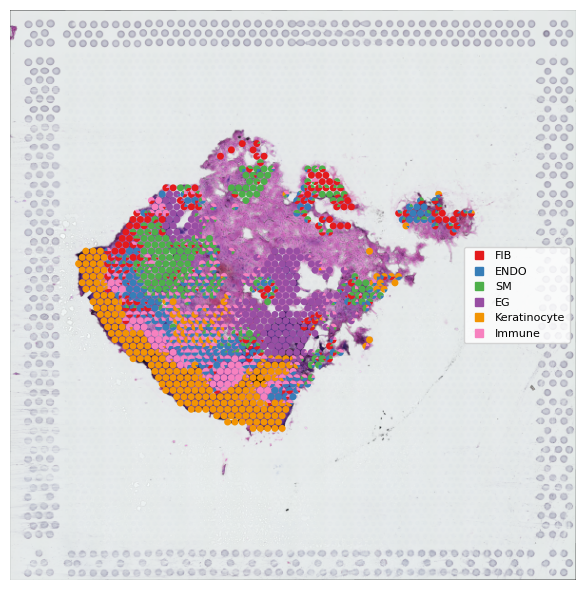

In [23]:
fig= scc.spatialDimPlot(sub, proportion=ctd, point_size=1.5)

## Spatial feature plot — pathway gene expression

`spatialFeaturePlot` displays gene expression patterns. The R signature
accepts `signaling=...` and resolves the gene set internally; the Python
port asks for explicit gene names via `features=` (we use
`extractEnrichedLR` with `geneLR_return=True` to fetch them).

All significant pathways live under `sub.uns['cellchat']['netP']['pathways']`.

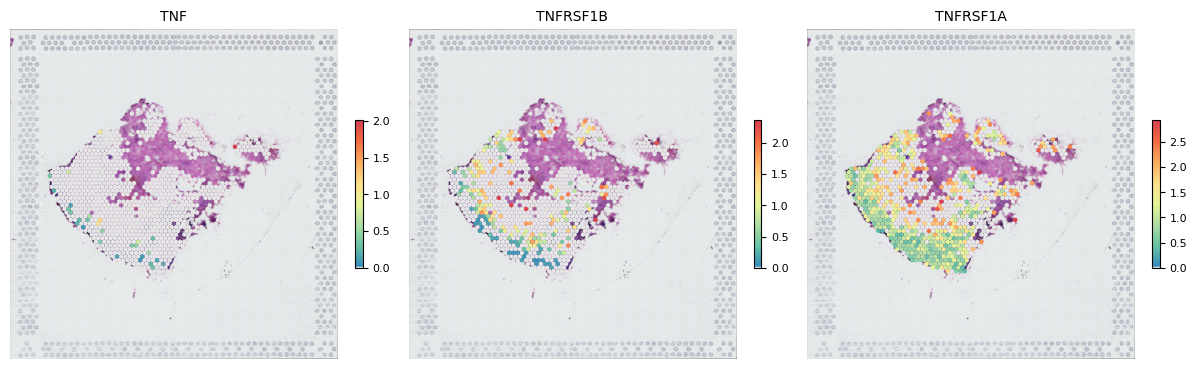

In [24]:
pathway_show = "TNF"
gene_pkg = scc.extractEnrichedLR(
    sub, signaling=[pathway_show], do_group=False, geneLR_return=True
)
path_genes = [g for g in gene_pkg["geneLR"] if g in adata.var_names]
fig = scc.spatialFeaturePlot(
    sub,
    features=path_genes[:8],
    color_heatmap="Spectral",
    point_size=1.3,
)

### Spatial feature plot — top L-R pair (binary)

`extractEnrichedLR` returns a `{pairLR, geneLR}` dict for a given pathway.
Setting `cutoff=...` in `spatialFeaturePlot` binarises and overlays the
ligand and receptor expression on a single map.

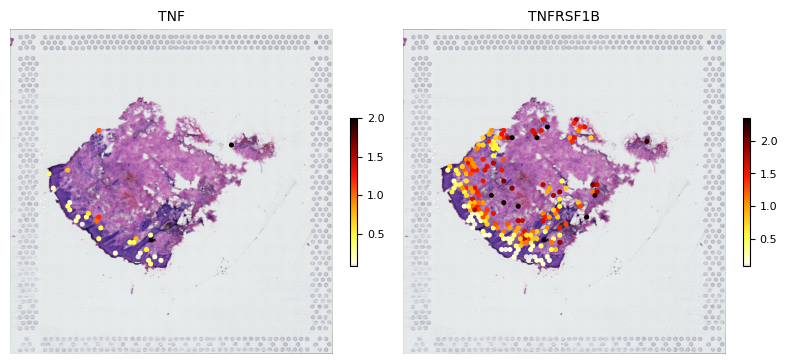

In [25]:
enrLR_pkg = scc.extractEnrichedLR(
    sub, signaling=[pathway_show], do_group=False, geneLR_return=True
)
lr_genes = [g for g in enrLR_pkg["geneLR"][:2] if g in adata.var_names]
if lr_genes:
    fig = scc.spatialFeaturePlot(
        sub, features=lr_genes, cutoff=0.05, point_size=1.5
    )
else:
    print("no L-R genes from this pathway are in adata.var_names; skipping")

## Visualise inferred communication at the individual-cell level
### Outgoing / incoming scores of pathways and L-R pairs

`spatialVisual_scoring` overlays per-cell sender / receiver scores on the
tissue. The Python port currently wires `slot_name='net'` (LR pairs); the
`netP` branch needs a per-cell pathway centrality which the port does not
compute.

showing LR: TGFB1_TGFBR1_TGFBR2


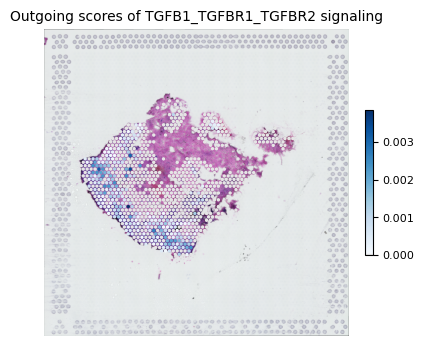

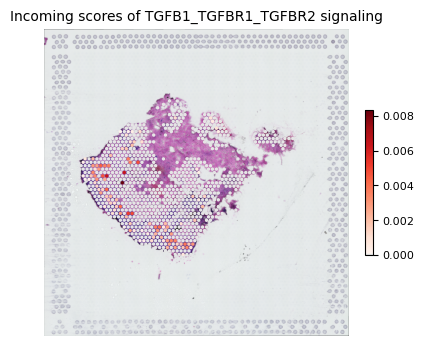

In [26]:
LR_sig_cell_list = list(sub.uns["cellchat"]["net"].get("LR.sig.cell", []))
LR_pick = LR_sig_cell_list[0]
print(f"showing LR: {LR_pick}")

scc.spatialVisual_scoring(
    sub, signaling=LR_pick, slot_name="net", do_group=False,
    measure=("outdeg",), do_binary=False, color_heatmap="Blues", point_size=1,
)
plt.show()
scc.spatialVisual_scoring(
    sub, signaling=LR_pick, slot_name="net", do_group=False,
    measure=("indeg",), do_binary=False, color_heatmap="Reds", point_size=1,
)
plt.show()


Setting `merge=True` overlays outgoing and incoming scores on a single
panel.

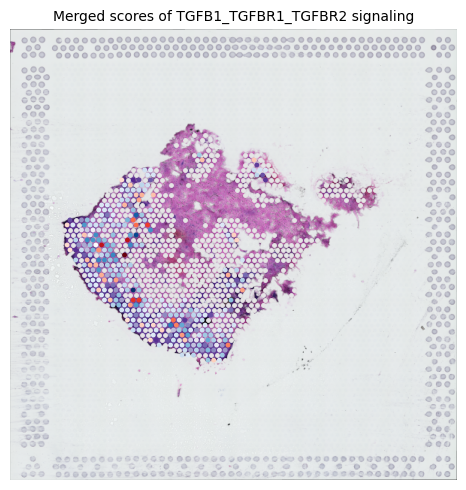

In [27]:
scc.spatialVisual_scoring(
    sub, signaling=LR_pick, slot_name="net", do_group=False,
    merge=True, do_binary=False, point_size=1,
)
plt.show()

## Visualise inferred communication at the cell-group level
### Circle plot of a signaling pathway

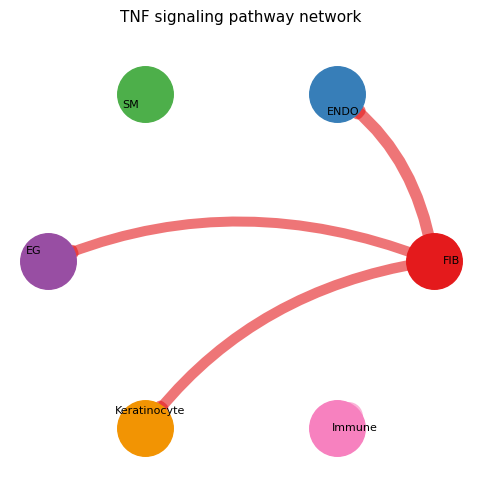

In [28]:
scc.netVisual_aggregate(sub, signaling=pathway_show, layout="circle")
plt.show()

### Major senders and receivers — `netAnalysis_signalingRole_network`

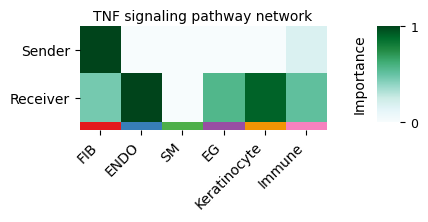

In [29]:
fig = scc.netAnalysis_signalingRole_network(
    sub, signaling=[pathway_show], slot_name="netP",
    measure=("outdeg", "indeg"),
    measure_name=("Sender", "Receiver"),
    width=8, height=3, font_size=10,
)

### Pathway-level heatmap

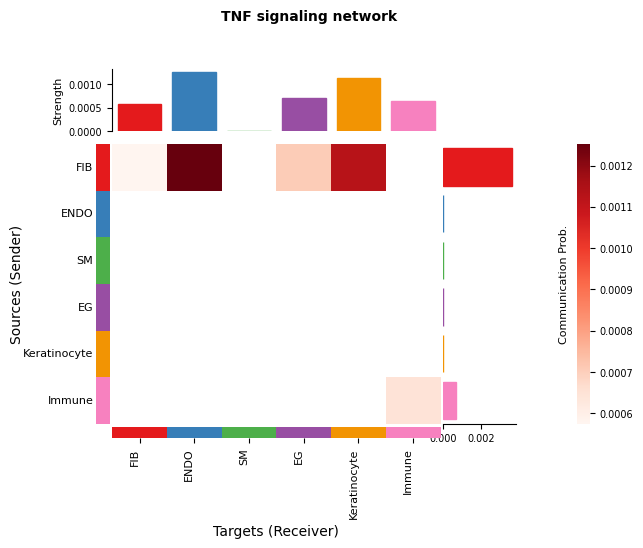

In [30]:
fig = scc.netVisual_heatmap(
    sub, slot_name="netP", signaling=pathway_show, color_heatmap=("Reds",)
)

## Hot-spots analysis
### Incoming hotspot scores of secreted vs cell-cell-contact signaling

`spatialGiPlot` overlays the local-Getis-Ord *G*ᵢ score for a given
signaling subset. The Python port takes a single LR pair name per call
(rather than a vector of indices like the R version), so we pick a
representative LR from each annotation.

In [31]:
LRsig_post_filter = sub.uns["cellchat"]["LR"]["LRsig"]
secreted_set = set(
    LRsig_post_filter.loc[
        LRsig_post_filter["annotation"].astype(str) == "Secreted Signaling",
        "interaction_name",
    ]
)
contact_set = set(
    LRsig_post_filter.loc[
        LRsig_post_filter["annotation"].astype(str) == "Cell-Cell Contact",
        "interaction_name",
    ]
)
LR_paracrine = [nm for nm in LR_sig_cell_list if nm in secreted_set]
LR_juxta = [nm for nm in LR_sig_cell_list if nm in contact_set]
print(f"#paracrine LR.sig.cell={len(LR_paracrine)}, #juxtracrine={len(LR_juxta)}")

#paracrine LR.sig.cell=403, #juxtracrine=183


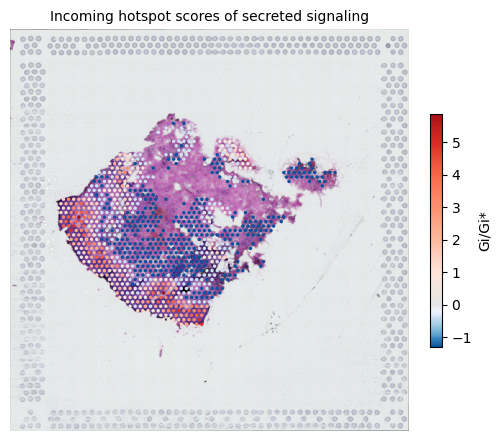

In [32]:
if LR_paracrine:
    fig = scc.spatialGiPlot(
        sub, plot_title="Incoming hotspot scores of secreted signaling",
        slot_name="net", signaling_name=LR_paracrine[0],
        measure=("indeg",), measure_name=("incoming",), point_size=1,
    )

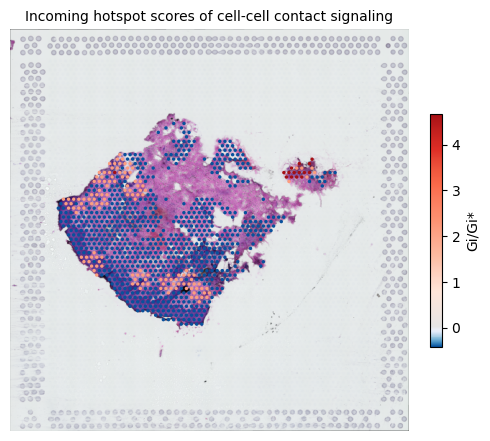

In [33]:
if LR_juxta:
    fig = scc.spatialGiPlot(
        sub, plot_title="Incoming hotspot scores of cell-cell contact signaling",
        slot_name="net", signaling_name=LR_juxta[0],
        measure=("indeg",), measure_name=("incoming",), point_size=1,
    )

### Categorise spots based on the hot-spot incoming scores

Unlike R's `spatialGiPlot(return.object=TRUE)`, the Python port does not
write *G*ᵢ statistics back to `adata.obs`. We replicate the categorisation
by computing local-*G*ᵢ on the cell-level summed indeg of paracrine LR
pairs, then label each spot Hot / Cold / Other from the sign and
significance of *G*ᵢ.

In [34]:
from scipy.stats import norm
from sklearn.neighbors import NearestNeighbors

# R-mirror access to per-LR-pair centrality: ``centr_value`` is the
# Python equivalent of R's ``centr.cell[measure, , signaling]`` indexing.
centr = sub.uns["cellchat"]["net"]["centr.cell"]
indeg_sum = np.zeros(sub.n_obs, dtype=float)
for nm in LR_paracrine:
    indeg_sum += scc.centr_value(centr, "indeg", nm)

coords = np.asarray(adata.obsm["spatial"], dtype=float)
nbrs = NearestNeighbors(n_neighbors=13).fit(coords)
_, idx = nbrs.kneighbors(coords)
n = coords.shape[0]
W = np.zeros((n, n))
for i in range(n):
    for j in idx[i, 1:]:
        W[i, j] = 1
xbar = float(indeg_sum.mean())
s2 = float(((indeg_sum - xbar) ** 2).mean())
G = np.zeros(n)
for i in range(n):
    wi = W[i]
    if s2 > 0:
        G[i] = (
            np.sum(wi * indeg_sum) - xbar * np.sum(wi)
        ) / np.sqrt(s2 * (n * np.sum(wi ** 2) - np.sum(wi) ** 2) / (n - 1))
pvals = 2 * (1 - norm.cdf(np.abs(G)))
sig = (pvals < 0.05) * G
label = np.where(sig > 0, "Hot", np.where(sig < 0, "Cold", "Other"))
sub.obs["SecretedHotspot"] = pd.Categorical(
    label, categories=["Hot", "Cold", "Other"]
)
print(
    f"Hot={int((label=='Hot').sum())} "
    f"Cold={int((label=='Cold').sum())} "
    f"Other={int((label=='Other').sum())}"
)


Hot=209 Cold=198 Other=498


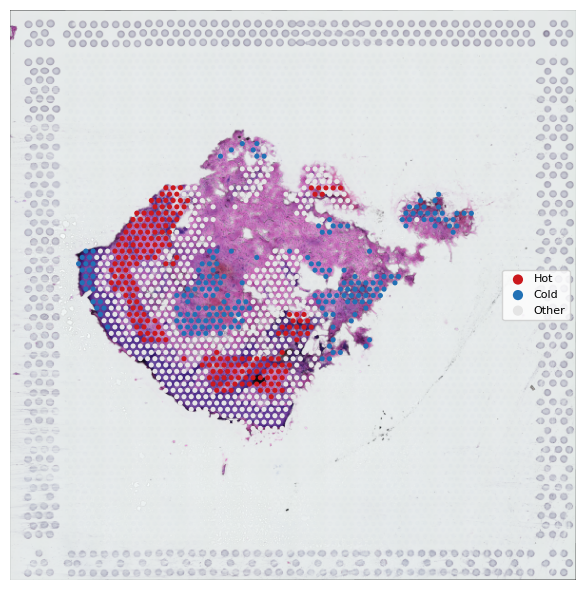

In [35]:
fig = scc.spatialDimPlot(
    sub, group_by="SecretedHotspot", point_size=1.5,
    color_use=["#cb181d", "#2171b5", "#E5E5E5"],
)

### Visualise the enriched cell groups (categorical Lee plot)

`spatialLeePlot` with categorical groupings infers spatial co-occurrence
between cell-type identities and the Hot/Cold/Other label.

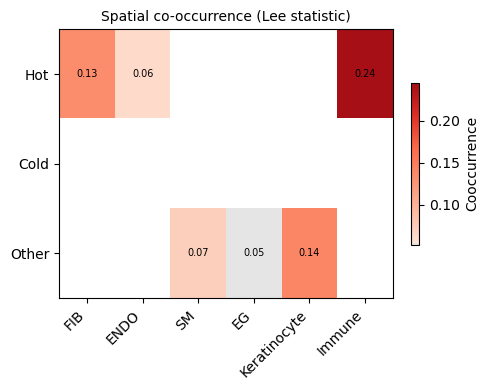

In [36]:
fig = scc.spatialLeePlot(
    sub, group_by2="SecretedHotspot",
    cutoff_lee=0.05, y_levels=("Hot", "Cold", "Other"),
)

### Identify the enriched signaling — `rankNet`

`rankNet` ranks signaling pathways by overall communication strength. We
split the ranking by `signaling_type`.

In [37]:
ranks = {}
for sig_type in ("Secreted Signaling", "ECM-Receptor", "Cell-Cell Contact"):
    ranks[sig_type] = scc.rankNet(
        sub, mode="single", slot_name="netP", measure="weight",
        signaling_type=[sig_type],
    )
    print(f"{sig_type}: {len(ranks[sig_type])} rows")
ranks["Secreted Signaling"].head()

Secreted Signaling: 64 rows
ECM-Receptor: 9 rows
Cell-Cell Contact: 49 rows


,name,contribution,contribution.scaled,group
0,IL6,0.000425,0.128809,pathways
1,IGF,0.000872,0.141950,pathways
2,PROCR,0.000928,0.143227,pathways
3,APJ,0.001102,0.146831,pathways
4,KIT,0.001374,0.151747,pathways


Restore the per-measure `centr.cell` schema (the topics layer needs that
form, while we'd swapped to dict-of-dicts above for the visualisations).

In [38]:
# Cell #42 no longer overwrites centr.cell, so no restore is needed.
# (Kept as a placeholder so cell numbering matches earlier docs.)


If you have many signaling pathways you can collect the rank tables for
further inspection.

In [39]:
rank_df = pd.concat(
    [df.assign(type=k) for k, df in ranks.items()], ignore_index=True
)
rank_df.sort_values("contribution", ascending=False).head()

,name,contribution,contribution.scaled,group,type
72,COLLAGEN,0.662848,2.431849,pathways,ECM-Receptor
71,LAMININ,0.444675,1.233940,pathways,ECM-Receptor
70,THBS,0.120245,0.472093,pathways,ECM-Receptor
63,ncWNT,0.083500,0.402753,pathways,Secreted Signaling
62,SEMA3,0.072279,0.380631,pathways,Secreted Signaling


### `netAnalysis_contribution` — rank L-R pairs within a pathway

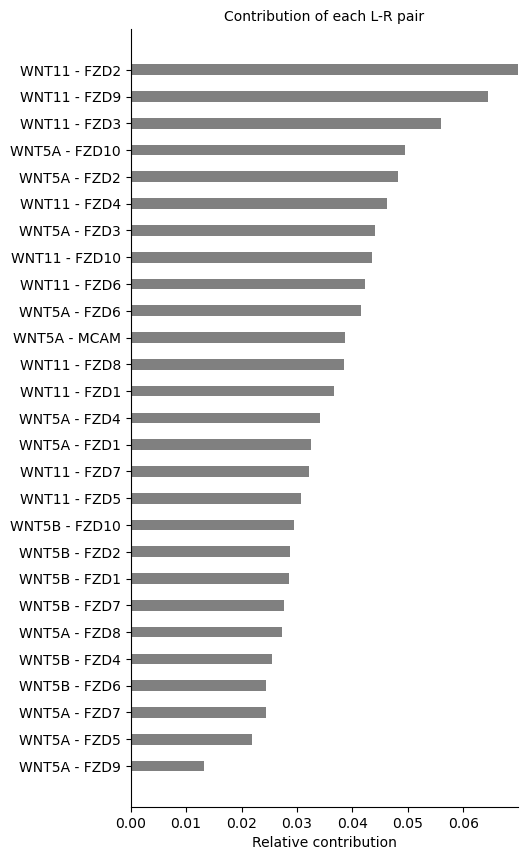

In [40]:
contribution_pw = "ncWNT" if "ncWNT" in pathways else pathway_show
fig = scc.netAnalysis_contribution(sub, signaling=contribution_pw)

## Spatial cooccurrence analysis

The Lee statistic captures spatial co-occurrence between two features.
The R tutorial demonstrates `spatialLeePlot` with continuous matrix
inputs (`mat1` = ligand/receptor expression of the CXCL pathway,
`mat2` = per-cell `indeg` scores for the IL17 LR pairs).

**Note**: the Python port of `spatialLeePlot` currently supports only the
categorical `group_by1` / `group_by2` branch — passing continuous
matrices raises a matmul shape error. We therefore re-use the categorical
Hot/Cold/Other call from above as the canonical Python equivalent and
leave a placeholder for the continuous-matrix call until the port catches
up.

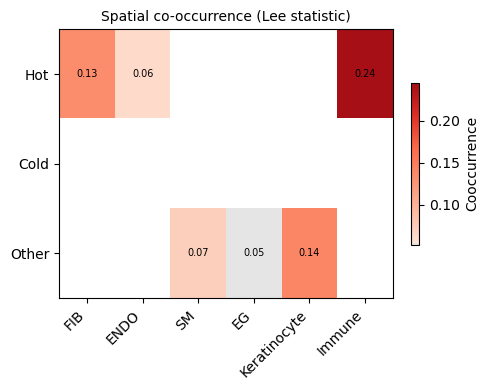

In [41]:
# Categorical equivalent (already shown above).
fig = scc.spatialLeePlot(
    sub, group_by2="SecretedHotspot",
    cutoff_lee=0.05, y_levels=("Hot", "Cold", "Other"),
)

## CCC topic analysis
### CCC topic identification

`identifyCellTopics` runs an NMF-based decomposition of the per-cell
incoming (or outgoing) signaling profile to identify recurring "topics"
of cell-cell communication. The rank `topic_k` can be selected
automatically (pass a sequence) or manually.

In [42]:
topic_k = 12
scc.identifyCellTopics(
    sub, slot_name="net", pattern="incoming",
    topic_k=(topic_k,), verbose=False,
)

AnnData object with n_obs × n_vars = 905 × 1200
    obs: 'orig.ident', 'nCount_Spatial', 'nFeature_Spatial', 'final.clusters', 'active_ident', 'array_row', 'array_col', 'in_tissue', 'cellchat_idents', 'Getis.Ord.Gi.incoming.TGFB1_TGFBR1_TGFBR2', 'Getis.Ord.Gi.incoming.TGFB1_TGFBR1_TGFBR2.p', 'Getis.Ord.Gi.incoming.PCDHB4_PCDHB4', 'Getis.Ord.Gi.incoming.PCDHB4_PCDHB4.p', 'SecretedHotspot'
    var: 'highly_variable_signaling'
    uns: 'spatial', 'predictions_columns', 'cellchat', 'alra_k'
    obsm: 'X_pca', 'X_umap', 'spatial', 'predictions'
    layers: 'counts', 'data_signaling'

### Visualisation of CCC topics — spatial distribution

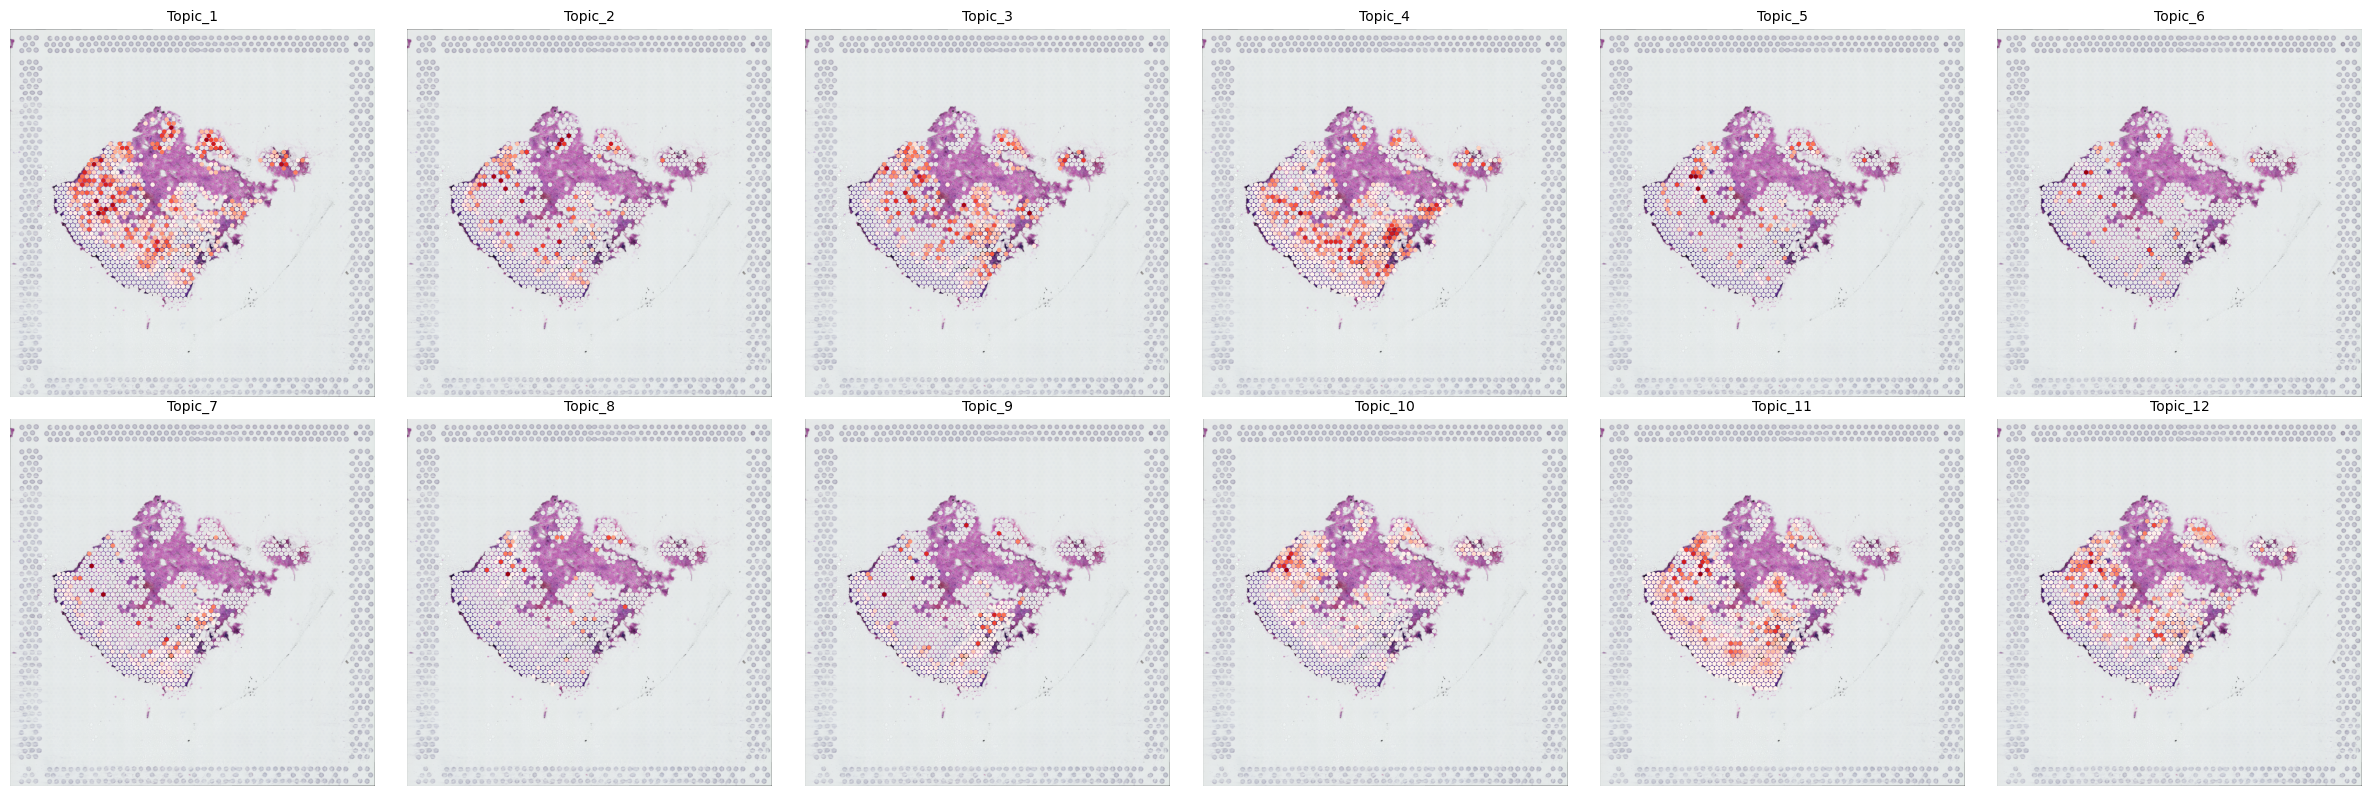

In [43]:
fig = scc.spatialTopicPlot(
    sub, pattern="incoming", color_heatmap="Reds",
    show_legend=False, point_size=1.3, ncol=topic_k // 2,
)

### Cell-type composition of each topic

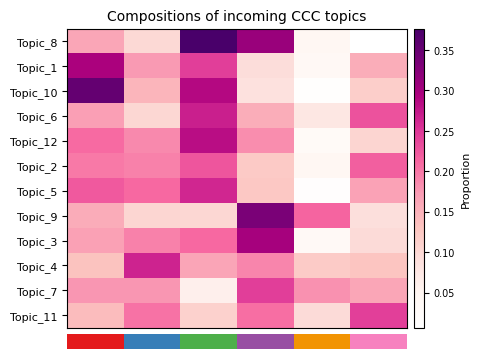

In [44]:
fig = scc.netVisual_TopicComposition(
    sub, y_group="topicIn", x_group=None, cluster_rows=True
)

### Top L-R pairs and signaling pathways per topic

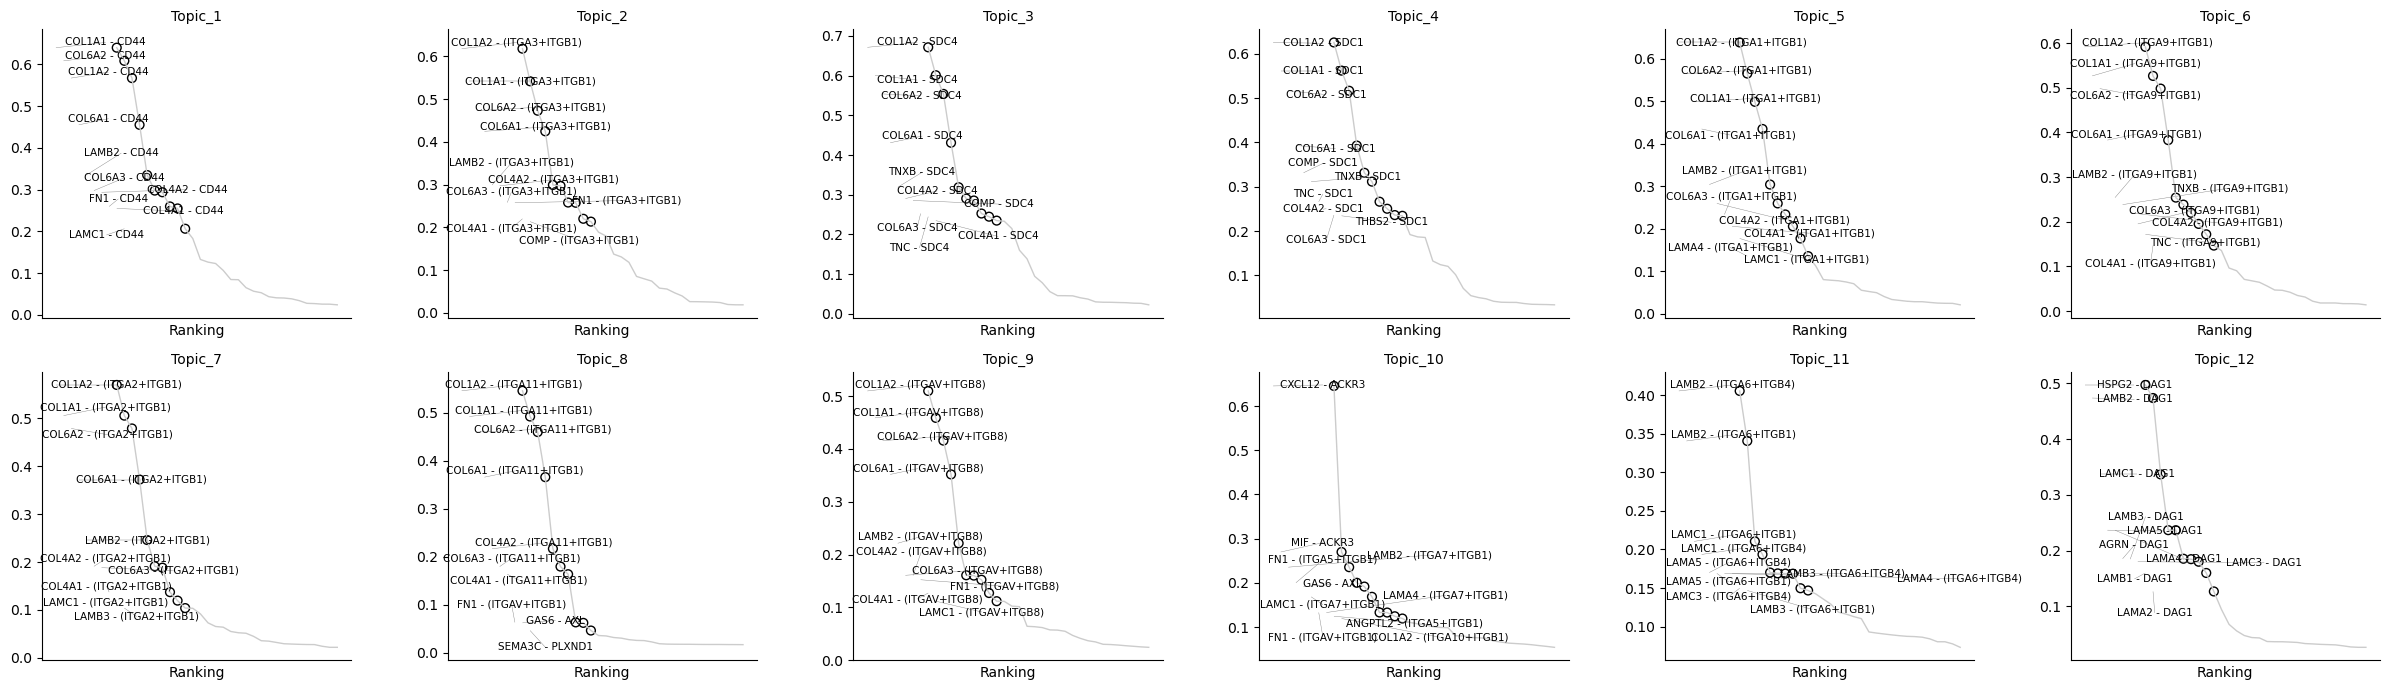

In [45]:
fig = scc.netVisual_TopicSignaling(
    sub, pattern="incoming", ncol=topic_k // 2
)

## Save the Spatial CellChat object

All CellChat state lives under `sub.uns['cellchat']`. To persist the
annotated AnnData simply call `sub.write_h5ad(...)`. Uncomment to save.

In [46]:
# sub.write_h5ad("chat_Downstream.h5ad")